# Оценка моделей на val и test

Прогоняет full-rank оценку (HR@K, NDCG@K) для указанных чекпойнтов на **val** и **test** сплитах.

Поддерживаемые модели: **SASRec**, **DreamRec**, **DreamRecText**, **FM-Text (FlowMatcher)**.

Что нужно сделать: в ячейке `MODELS` укажи путь к директории чекпойнта и конфиг для каждой модели. Отключить модель — `'enabled': False`.

In [1]:
import sys
import pickle
from pathlib import Path

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.append('../src')
from data import build_dataloaders
from evaluate import evaluate
from models.sasrec import SASRec
from models.dreamrec import DreamRec
from models.dreamrec_text import DreamRecText
from models.flow_matcher import FlowMatcher

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


## Конфиг: какие чекпойнты оценивать

`type` — один из `sasrec`, `dreamrec`, `dreamrec_text`, `fm_text`.  
`ckpt` — директория с `best.pt` / `latest.pt`.  
`config` — yaml, по которому обучалась модель (нужен для размерностей архитектуры).

In [2]:
# ════════════════════════════════════════════════════════════════════
# Укажи здесь свои чекпойнты (edit ckpt-пути под свои прогоны)
#
# Опциональные override'ы (перекрывают конфиг — retrieval_metric НЕ хранится
# в чекпойнте, поэтому если конфиг был изменён после обучения, задай явно):
#   'retrieval_metric': 'l2' | 'dot' | 'cosine'   — для dreamrec / dreamrec_text / fm_text
#   'w_cfg': float                                 — сила CFG при сэмплинге
#   'num_steps': int                               — шагов Euler ODE (только fm_text)
# ════════════════════════════════════════════════════════════════════
MODELS = {
    'SASRec':       {'type': 'sasrec',        'ckpt': '../checkpoints/sasrec_baseline',               'config': '../configs/sasrec.yaml',        'enabled': True},
    'Learned_DDPM':     {'type': 'dreamrec',      'ckpt': '../checkpoints/dreamrec_l2_nocfg',             'config': '../configs/dreamrec.yaml',      'enabled': True},
    'FrozenText_DDPM': {'type': 'dreamrec_text', 'ckpt': '../checkpoints/dreamrec_text_pca_cosine_nocfg', 'config': '../configs/dreamrec_text.yaml', 'enabled': True, 'retrieval_metric': 'cosine'},
    'FrozenText_FM':      {'type': 'fm_text',       'ckpt': '../checkpoints/fm_text_cosine_6',              'config': '../configs/fm_text.yaml',       'enabled': True, 'retrieval_metric': 'cosine'},
}

# ─────────────────────────────────────────────────────────────────────
DATA_DIR        = Path('../data/ATG')
EMB_PATH        = DATA_DIR / '3large_emb.pickle'
WHITENING_CACHE = Path('../data/processed/whitening_cache.npz')
PADDING_IDX     = 11924
N_ITEMS         = PADDING_IDX
BATCH_SIZE      = 256
TOP_K           = (10, 20)
SEED            = 42
N_RUNS          = 5      # прогонов с разными сидами шума (mean ± std)

In [3]:
# ленивая загрузка сырых TEM-эмбеддингов (нужны только text-моделям)
_emb_raw = None
def get_emb():
    global _emb_raw
    if _emb_raw is None:
        with open(EMB_PATH, 'rb') as f:
            _emb_raw = pickle.load(f).astype(np.float32)
        print(f'Loaded embeddings: {_emb_raw.shape}')
    return _emb_raw


def load_config(path):
    with open(path) as f:
        return yaml.safe_load(f)


def build_model(spec, cfg):
    """Собирает модель по конфигу. Веса/буферы приедут из чекпойнта.

    retrieval_metric НЕ хранится в чекпойнте — если в spec есть override,
    он важнее значения из конфига (конфиг мог быть изменён после обучения).
    """
    mtype       = spec['type']
    d           = cfg.get('data', {})
    padding_idx = d.get('padding_idx', PADDING_IDX)
    max_seq_len = d.get('max_seq_len', 10)

    if mtype == 'sasrec':
        m = cfg['model']
        return SASRec(
            n_items=d.get('n_items', N_ITEMS), padding_idx=padding_idx,
            d_model=m['d_model'], n_heads=m['n_heads'], n_layers=m['n_layers'],
            d_ff=m['d_ff'], dropout=m.get('dropout', 0.0), max_seq_len=max_seq_len,
            tie_weights=m.get('tie_weights', True), loss=m.get('loss', 'infonce'),
            neg_ratio=m.get('neg_ratio', 64), temperature=m.get('temperature', 0.07),
        )

    if mtype == 'dreamrec':
        m = cfg['model']
        return DreamRec(
            n_items=d.get('n_items', N_ITEMS), padding_idx=padding_idx,
            d_model=m['d_model'], n_heads=m['n_heads'], d_ff=m['d_ff'],
            dropout=m.get('dropout', 0.1), max_seq_len=max_seq_len,
            T=m['T'], beta_schedule=m.get('beta_schedule', 'exp'),
            p_uncond=m.get('p_uncond', 0.0),
            w_cfg=spec.get('w_cfg', m.get('w_cfg', 0.0)),
            retrieval_metric=spec.get('retrieval_metric', m.get('retrieval_metric', 'l2')),
        )

    if mtype == 'dreamrec_text':
        m = cfg['model']
        return DreamRecText(
            item_embeddings_raw=get_emb(), padding_idx=padding_idx,
            use_pca=m.get('use_pca', True), n_components=m.get('n_components', 256),
            per_component_whitening=m.get('per_component_whitening', True),
            whitening_cache_path=d.get('whitening_cache', WHITENING_CACHE),
            n_heads=m['n_heads'], d_ff=m['d_ff'], dropout=m.get('dropout', 0.1),
            max_seq_len=max_seq_len, T=m['T'], beta_schedule=m.get('beta_schedule', 'exp'),
            p_uncond=m.get('p_uncond', 0.0),
            w_cfg=spec.get('w_cfg', m.get('w_cfg', 0.0)),
            retrieval_metric=spec.get('retrieval_metric', m.get('retrieval_metric', 'l2')),
        )

    if mtype == 'fm_text':
        enc, den, fm = cfg['encoder'], cfg['denoiser'], cfg['flow_matching']
        return FlowMatcher(
            item_embeddings_raw=get_emb(), padding_idx=padding_idx,
            n_components=d.get('n_components', 256),
            per_component_whitening=fm.get('per_component_whitening', False),
            whitening_cache_path=d.get('whitening_cache', WHITENING_CACHE),
            d_hidden=enc['d_hidden'], d_cond=enc['d_cond'],
            encoder_layers=enc['layers'], encoder_heads=enc['heads'],
            encoder_d_ff=enc['d_ff'], encoder_dropout=enc.get('dropout', 0.1),
            max_seq_len=max_seq_len,
            denoiser_d_block=den['d_block'], denoiser_d_ff=den['d_ff'],
            denoiser_n_blocks=den['n_blocks'], denoiser_time_emb_dim=den['time_emb_dim'],
            denoiser_dropout=den.get('dropout', 0.0),
            p_uncond=fm.get('p_uncond', 0.1),
            retrieval_metric=spec.get('retrieval_metric', fm.get('retrieval_metric', 'dot')),
        )

    raise ValueError(f'Unknown model type: {mtype!r}')


def eval_params(spec, cfg):
    """num_steps / w_cfg для evaluate().

    Число шагов сэмплинга берётся из конфига (eval.num_sample_steps), с fallback:
      fm_text        → Euler ODE, дефолт 50;
      dreamrec/_text → DDPM reverse, дефолт = T (полная цепочка; < T = respaced);
      sasrec         → сэмплинга нет, args игнорируются.
    spec может переопределить через 'num_steps' / 'w_cfg'.
    """
    ev = cfg.get('eval', {})
    if spec['type'] == 'fm_text':
        ns = spec.get('num_steps', ev.get('num_sample_steps', 50))
        w  = spec.get('w_cfg',     cfg['flow_matching'].get('w_cfg', 1.0))
        return int(ns), float(w)
    if spec['type'] in ('dreamrec', 'dreamrec_text'):
        m  = cfg['model']
        ns = spec.get('num_steps', ev.get('num_sample_steps', m.get('T', 1000)))
        w  = spec.get('w_cfg',     m.get('w_cfg', 0.0))
        return int(ns), float(w)
    return 1, 0.0   # sasrec — сэмплинга нет


def load_ckpt(model, ckpt_dir):
    ckpt_dir  = Path(ckpt_dir)
    ckpt_path = ckpt_dir / 'best.pt'
    if not ckpt_path.exists():
        ckpt_path = ckpt_dir / 'latest.pt'
    if not ckpt_path.exists():
        raise FileNotFoundError(f'Нет best.pt/latest.pt в {ckpt_dir}')
    ckpt = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ckpt['model_state'])
    ema_shadow = ckpt.get('ema_shadow', {})
    if ema_shadow:
        for name, param in model.named_parameters():
            if name in ema_shadow:
                param.data.copy_(ema_shadow[name].to(device))
    model.eval()
    return ckpt, ckpt_path

## Сборка и загрузка всех моделей

In [4]:
models = {}
for name, spec in MODELS.items():
    if not spec.get('enabled', True):
        print(f'{name:<14} skipped (disabled)')
        continue
    cfg   = load_config(spec['config'])
    model = build_model(spec, cfg).to(device)
    ckpt, path = load_ckpt(model, spec['ckpt'])
    ns, w = eval_params(spec, cfg)
    rm = getattr(model, 'retrieval_metric', '-')
    models[name] = {'model': model, 'type': spec['type'], 'cfg': cfg,
                    'ckpt_dir': Path(spec['ckpt']), 'num_steps': ns, 'w_cfg': w}
    ep = ckpt.get('epoch', '?')
    n_par = model.param_summary()['total_trainable']
    print(f'{name:<14} {spec["type"]:<14} epoch={ep}  params={n_par:,}  '
          f'retrieval={rm}  w_cfg={w}  ({path.name})')

print(f'\nЗагружено моделей: {len(models)}')

SASRec         sasrec         epoch=205  params=1,726,208  retrieval=-  w_cfg=0.0  (best.pt)
Learned_DDPM   dreamrec       epoch=160  params=863,552  retrieval=l2  w_cfg=0.0  (best.pt)
Loaded embeddings: (11924, 3072)
Loading whitening from cache: data\processed\whitening_cache.npz
FrozenText_DDPM dreamrec_text  epoch=480  params=1,581,056  retrieval=cosine  w_cfg=0.0  (best.pt)
Loading whitening from cache: data\processed\whitening_cache.npz
FrozenText_FM  fm_text        epoch=100  params=9,235,712  retrieval=cosine  w_cfg=1.0  (best.pt)

Загружено моделей: 4


In [5]:
loaders = build_dataloaders(
    data_dir=DATA_DIR, batch_size=BATCH_SIZE, num_workers=0,
    splits=('val', 'test'),
)
print(f'Val:  {len(loaders["val"].dataset):,}')
print(f'Test: {len(loaders["test"].dataset):,}')

Val:  1,941
Test: 1,942


## Оценка

In [6]:
METRIC_NAMES = [f'{metric}@{k}' for k in TOP_K for metric in ('HR', 'NDCG')]
seeds        = [SEED + i * 100 for i in range(N_RUNS)]

# структура: runs[split][name][metric] = список значений по сидам
val_runs  = {name: {m: [] for m in METRIC_NAMES} for name in models}
test_runs = {name: {m: [] for m in METRIC_NAMES} for name in models}

for name, entry in models.items():
    print(f'Evaluating {name} ({N_RUNS} seeds)...')
    for split, store in [('val', val_runs), ('test', test_runs)]:
        for i, s in enumerate(seeds):
            print(f'  {split} run {i+1}/{N_RUNS} (seed={s})...', end='\r')
            torch.manual_seed(s)
            metrics = evaluate(
                model=entry['model'], dataloader=loaders[split],
                top_k_values=TOP_K, num_sample_steps=entry['num_steps'],
                w_cfg=entry['w_cfg'], device=device, show_progress=False,
            )
            for m in METRIC_NAMES:
                store[name][m].append(metrics[m])
        print(f'  {split}: done ({N_RUNS} seeds)      ')
print('Done')

Evaluating SASRec (5 seeds)...
  val: done (5 seeds)      
  test: done (5 seeds)      
Evaluating Learned_DDPM (5 seeds)...
  val: done (5 seeds)      
  test: done (5 seeds)      
Evaluating FrozenText_DDPM (5 seeds)...
  val: done (5 seeds)      
  test: done (5 seeds)      
Evaluating FrozenText_FM (5 seeds)...
  val: done (5 seeds)      
  test: done (5 seeds)      
Done


In [7]:
COLS = METRIC_NAMES

def _random_vals():
    row = {}
    for k in TOP_K:
        row[f'HR@{k}']   = k / N_ITEMS
        row[f'NDCG@{k}'] = sum(1.0 / np.log2(r + 2) for r in range(k)) / N_ITEMS
    return row

def mean_std_table(runs):
    # Таблица: строки-модели, значения 'mean ± std' по сидам
    rows = {name: {m: f'{np.mean(md[m]):.4f} ± {np.std(md[m]):.4f}' for m in COLS}
            for name, md in runs.items()}
    rows['Random'] = {m: f'{v:.4f}' for m, v in _random_vals().items()}
    return pd.DataFrame(rows).T[COLS]

def means(runs):
    return {name: {m: float(np.mean(md[m])) for m in COLS} for name, md in runs.items()}

def stds(runs):
    return {name: {m: float(np.std(md[m])) for m in COLS} for name, md in runs.items()}

# средние/std для графиков ниже
val_results,  test_results  = means(val_runs),  means(test_runs)
val_std,      test_std      = stds(val_runs),   stds(test_runs)

### Val

In [8]:
print(f'VALIDATION  (mean ± std по {N_RUNS} сидам)')
print(mean_std_table(val_runs).to_string())

VALIDATION  (mean ± std по 5 сидам)
                           HR@10          NDCG@10            HR@20          NDCG@20
SASRec           0.0526 ± 0.0000  0.0351 ± 0.0000  0.0649 ± 0.0000  0.0381 ± 0.0000
Learned_DDPM     0.0126 ± 0.0009  0.0065 ± 0.0004  0.0197 ± 0.0013  0.0083 ± 0.0004
FrozenText_DDPM  0.0209 ± 0.0011  0.0169 ± 0.0007  0.0236 ± 0.0009  0.0176 ± 0.0007
FrozenText_FM    0.0225 ± 0.0012  0.0187 ± 0.0006  0.0256 ± 0.0010  0.0195 ± 0.0005
Random                    0.0008           0.0004           0.0017           0.0006


### Test

In [9]:
print(f'TEST  (mean ± std по {N_RUNS} сидам)')
print(mean_std_table(test_runs).to_string())

TEST  (mean ± std по 5 сидам)
                           HR@10          NDCG@10            HR@20          NDCG@20
SASRec           0.0433 ± 0.0000  0.0266 ± 0.0000  0.0566 ± 0.0000  0.0300 ± 0.0000
Learned_DDPM     0.0140 ± 0.0008  0.0070 ± 0.0002  0.0215 ± 0.0011  0.0089 ± 0.0004
FrozenText_DDPM  0.0205 ± 0.0012  0.0174 ± 0.0006  0.0236 ± 0.0011  0.0182 ± 0.0005
FrozenText_FM    0.0188 ± 0.0008  0.0160 ± 0.0004  0.0212 ± 0.0014  0.0166 ± 0.0002
Random                    0.0008           0.0004           0.0017           0.0006


## Сравнение моделей (val vs test)

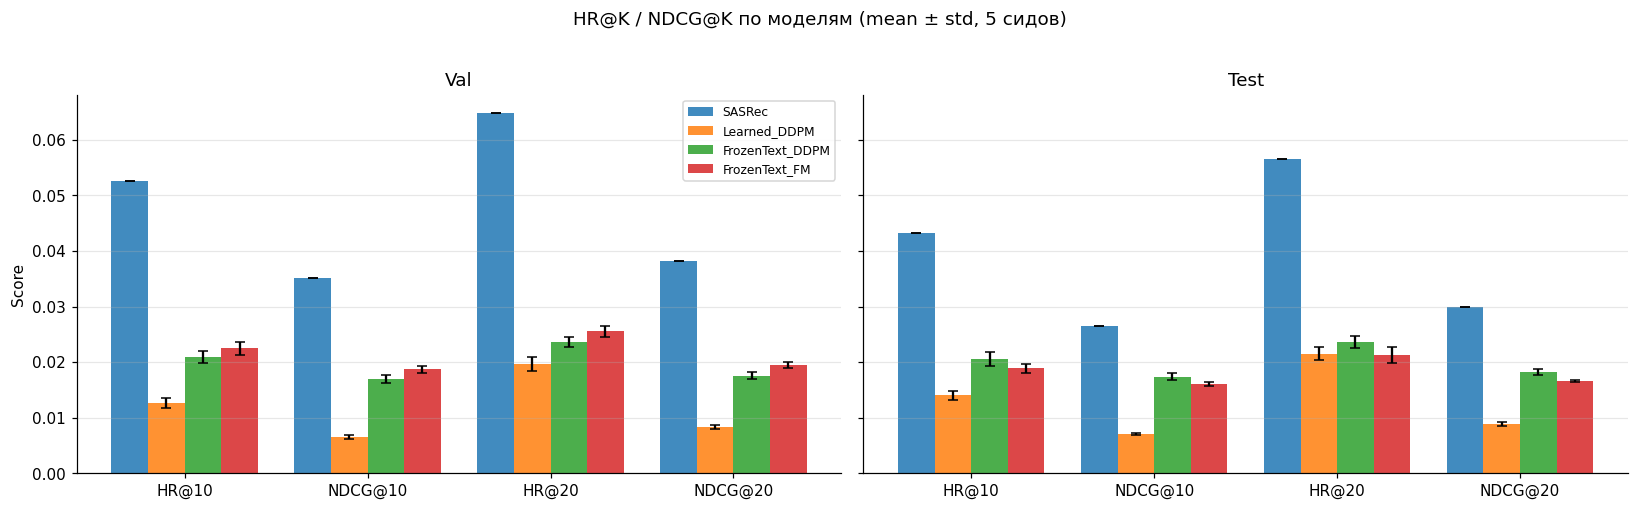

In [ ]:
names   = list(models.keys())
metrics = COLS
x       = np.arange(len(metrics))
width   = 0.8 / max(len(names), 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, res, err, title in [(axes[0], val_results, val_std, 'Val'),
                            (axes[1], test_results, test_std, 'Test')]:
    for i, name in enumerate(names):
        vals = [res[name][m] for m in metrics]
        yerr = [err[name][m] for m in metrics]
        ax.bar(x + i * width, vals, width, yerr=yerr, capsize=3, label=name, alpha=0.85)
    ax.set_xticks(x + width * (len(names) - 1) / 2)
    ax.set_xticklabels(metrics)
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('Score')
axes[0].legend(fontsize=8)
plt.suptitle(f'HR@K / NDCG@K по моделям (mean ± std, {N_RUNS} сидов)', y=1.02)
plt.tight_layout()
plt.show()

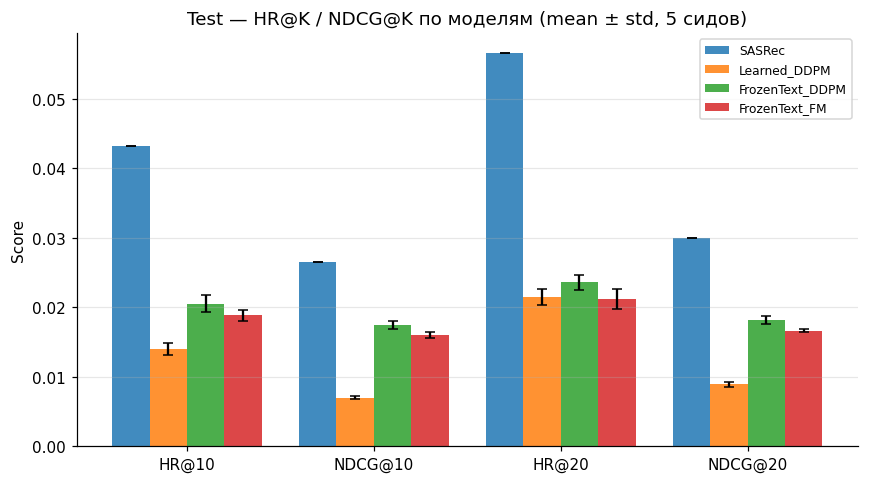

In [ ]:
names   = list(models.keys())
metrics = COLS
x       = np.arange(len(metrics))
width   = 0.8 / max(len(names), 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, name in enumerate(names):
    vals = [test_results[name][m] for m in metrics]
    yerr = [test_std[name][m] for m in metrics]
    ax.bar(x + i * width, vals, width, yerr=yerr, capsize=3, label=name, alpha=0.85)
ax.set_xticks(x + width * (len(names) - 1) / 2)
ax.set_xticklabels(metrics)
ax.set_ylabel('Score')
ax.set_title(f'Test — HR@K / NDCG@K по моделям (mean ± std, {N_RUNS} сидов)')
ax.grid(axis='y', alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Кривые обучения (val HR@20 / NDCG@20 из log_val.csv)

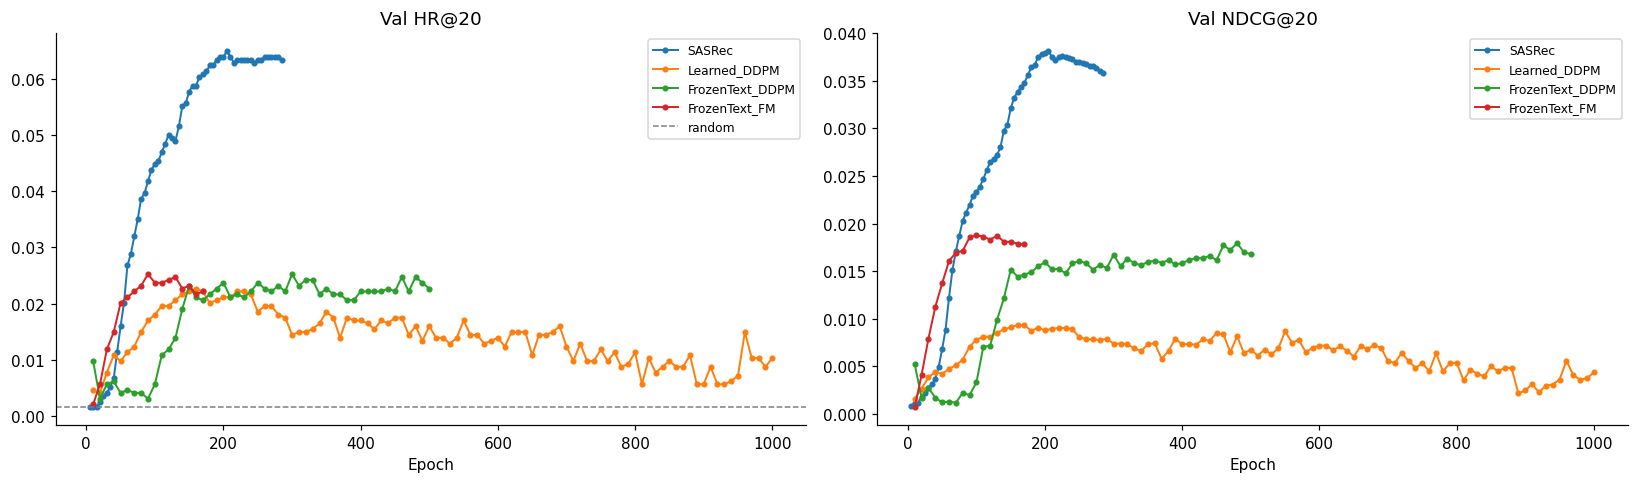

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, entry in models.items():
    log_path = entry['ckpt_dir'] / 'log_val.csv'
    if not log_path.exists():
        print(f'{name}: нет {log_path.name}')
        continue
    log = pd.read_csv(log_path)
    log = log[pd.to_numeric(log['epoch'], errors='coerce').notna()].copy()
    log['epoch'] = log['epoch'].astype(int)
    if 'HR@20' in log.columns:
        axes[0].plot(log['epoch'], log['HR@20'], 'o-', ms=3, lw=1.3, label=name)
    if 'NDCG@20' in log.columns:
        axes[1].plot(log['epoch'], log['NDCG@20'], 'o-', ms=3, lw=1.3, label=name)

axes[0].axhline(20 / N_ITEMS, color='gray', ls='--', lw=1, label='random')
axes[0].set_xlabel('Epoch'); axes[0].set_title('Val HR@20');   axes[0].legend(fontsize=8)
axes[1].set_xlabel('Epoch'); axes[1].set_title('Val NDCG@20'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## NDCG@20 vs число шагов сэмплинга

Число шагов сэмплинга `num_sample_steps` теперь работает у **всех** генеративных моделей:
- **FM** (`fm_text`) — число шагов Euler ODE;
- **DDPM** (`dreamrec`, `dreamrec_text`) — respaced ancestral sampling: тот же стохастический reverse-процесс, но по равномерно прорежённой сетке из `num_steps` таймстепов (при `num_steps ≥ T` — полная цепочка). Логика зашита прямо в `sample()`, число шагов берётся из конфига (`eval.num_sample_steps`).

Ниже — свип по списку `STEP_LIST`: для каждого числа шагов прогоняем `N_RUNS` сидов и строим NDCG@20 (mean ± std). SASRec не участвует — у него нет сэмплинга.

FrozenText_DDPM (dreamrec_text): sweep по шагам [1, 5, 10, 20, 50, 100, 200] × 5 сидов...
  steps=1    NDCG@20=0.0120 ± 0.0002
  steps=5    NDCG@20=0.0153 ± 0.0005
  steps=10   NDCG@20=0.0162 ± 0.0006
  steps=20   NDCG@20=0.0163 ± 0.0002
  steps=50   NDCG@20=0.0178 ± 0.0003
  steps=100  NDCG@20=0.0179 ± 0.0003
  steps=200  NDCG@20=0.0183 ± 0.0003
FrozenText_FM (fm_text): sweep по шагам [1, 5, 10, 20, 50, 100, 200] × 5 сидов...
  steps=1    NDCG@20=0.0163 ± 0.0004
  steps=5    NDCG@20=0.0169 ± 0.0003
  steps=10   NDCG@20=0.0169 ± 0.0003
  steps=20   NDCG@20=0.0169 ± 0.0003
  steps=50   NDCG@20=0.0167 ± 0.0003
  steps=100  NDCG@20=0.0166 ± 0.0002
  steps=200  NDCG@20=0.0166 ± 0.0002


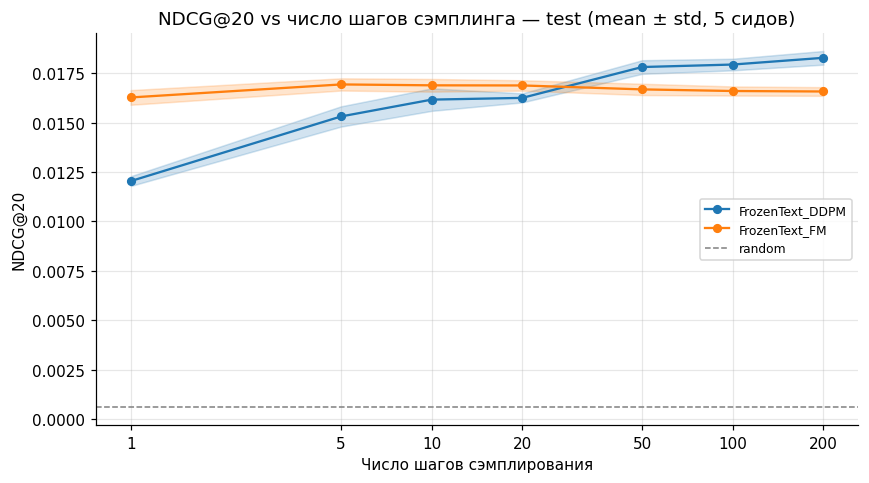

In [7]:
# ─────────────────────────────────────────────────────────────────────
# NDCG@K vs число шагов сэмплинга — для всех моделей с сэмплированием.
#   fm_text        → Euler ODE
#   dreamrec/_text → respaced ancestral DDPM (num_steps < T)
# SASRec не участвует (сэмплинга нет). Число шагов задаётся списком STEP_LIST.
# Ячейка самодостаточна: зависит только от models / loaders / seeds / evaluate.
# ─────────────────────────────────────────────────────────────────────
METRIC_NAMES = [f'{metric}@{k}' for k in TOP_K for metric in ('HR', 'NDCG')]
seeds        = [SEED + i * 100 for i in range(N_RUNS)]
STEP_LIST   = [1, 5, 10, 20, 50, 100, 200]   # число шагов сэмплинга
STEPS_SPLIT = 'test'                        # 'val' или 'test'
STEPS_K     = 20                            # NDCG@K для графика

metric_key      = f'NDCG@{STEPS_K}'
random_ndcg     = sum(1.0 / np.log2(r + 2) for r in range(STEPS_K)) / N_ITEMS  # random baseline
SAMPLING_TYPES  = ('fm_text', 'dreamrec_text')
sampling_models = {n: e for n, e in models.items() if e['type'] in SAMPLING_TYPES}

if not sampling_models:
    print('Нет моделей с сэмплированием — график пропущен.')
else:
    steps_curve = {}   # name -> {'mean': np.array, 'std': np.array}
    for name, entry in sampling_models.items():
        print(f'{name} ({entry["type"]}): sweep по шагам {STEP_LIST} × {N_RUNS} сидов...')
        means_, stds_ = [], []
        for ns in STEP_LIST:
            vals = []
            for s in seeds:
                torch.manual_seed(s)
                m = evaluate(
                    model=entry['model'], dataloader=loaders[STEPS_SPLIT],
                    top_k_values=TOP_K, num_sample_steps=ns,
                    w_cfg=entry['w_cfg'], device=device, show_progress=False,
                )
                vals.append(m[metric_key])
            means_.append(float(np.mean(vals)))
            stds_.append(float(np.std(vals)))
            print(f'  steps={ns:<4} {metric_key}={means_[-1]:.4f} ± {stds_[-1]:.4f}')
        steps_curve[name] = {'mean': np.array(means_), 'std': np.array(stds_)}

    # ── График ────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for name, cur in steps_curve.items():
        line, = ax.plot(STEP_LIST, cur['mean'], 'o-', lw=1.5, ms=5, label=name)
        ax.fill_between(STEP_LIST, cur['mean'] - cur['std'], cur['mean'] + cur['std'],
                        color=line.get_color(), alpha=0.2)
    ax.axhline(random_ndcg, color='gray', ls='--', lw=1, label='random')
    ax.set_xscale('log')
    ax.set_xticks(STEP_LIST)
    ax.set_xticklabels(STEP_LIST)
    ax.minorticks_off()
    ax.set_xlabel('Число шагов сэмплирования')
    ax.set_ylabel(metric_key)
    ax.set_title(f'{metric_key} vs число шагов сэмплинга — {STEPS_SPLIT} (mean ± std, {N_RUNS} сидов)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()